In [40]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from src.pipeline import (
    trivial_segmentation,
    simple_segmentation,
    trivial_restoration,
    simple_restoration
)

from src.data import (
    load_image,
    load_ground_truth,
    degrade_image
)

# Select one test sample
image_path, mask_path = test_pairs[0]

image = load_image(image_path)
ground_truth = load_ground_truth(mask_path)

print("Sample:", image_path.stem)
print("Image Shape:", image.shape)
print("Mask Shape:", ground_truth.shape)

Sample: cju5ekty5ckzf07550c9u3ckk
Image Shape: (512, 512, 3)
Mask Shape: (512, 512)


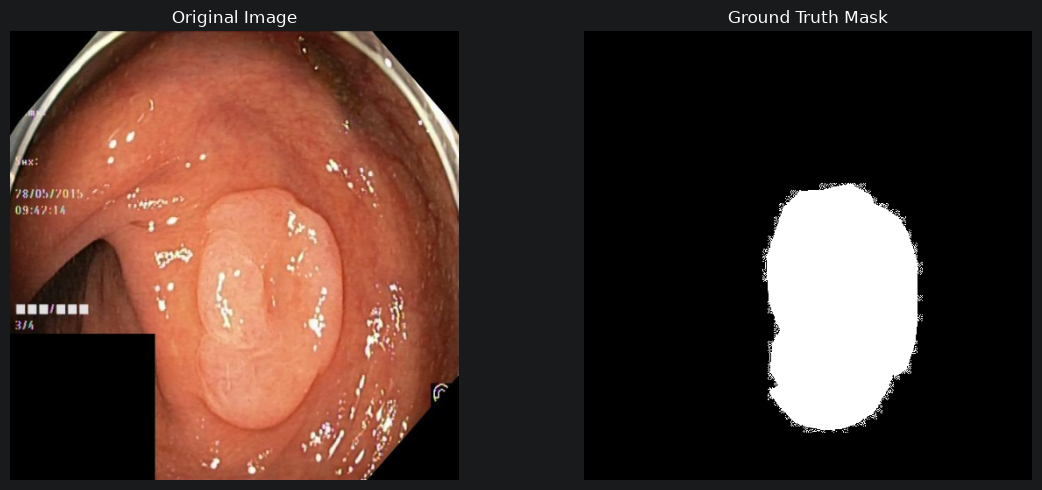

In [41]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(ground_truth, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

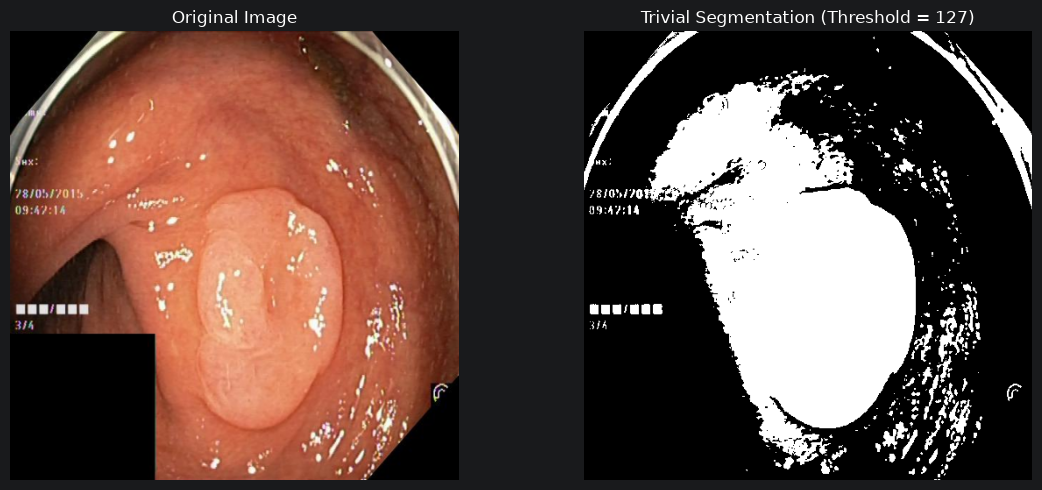

In [42]:
trivial_pred = trivial_segmentation(image)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(trivial_pred, cmap="gray")
plt.title("Trivial Segmentation (Threshold = 127)")
plt.axis("off")

plt.tight_layout()
plt.show()

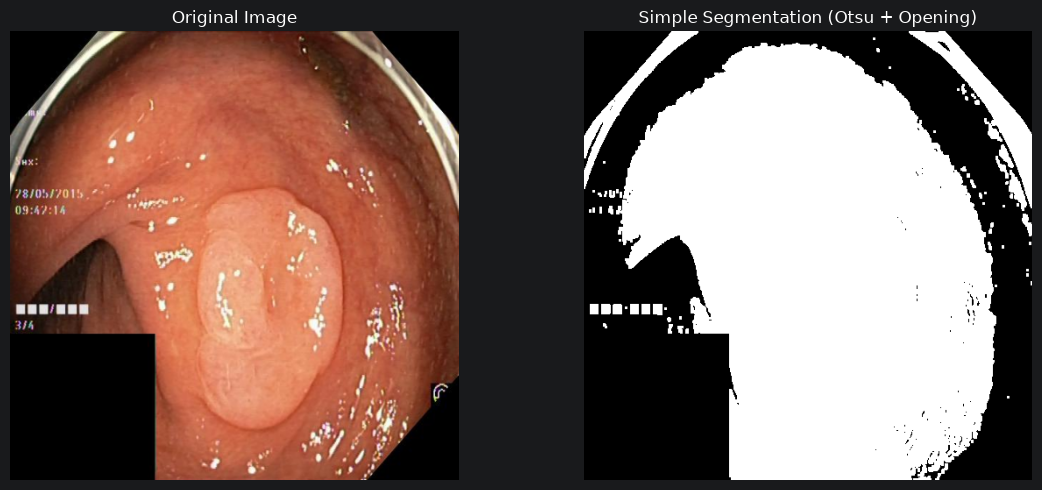

In [43]:
simple_pred = simple_segmentation(image)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(simple_pred, cmap="gray")
plt.title("Simple Segmentation (Otsu + Opening)")
plt.axis("off")

plt.tight_layout()
plt.show()

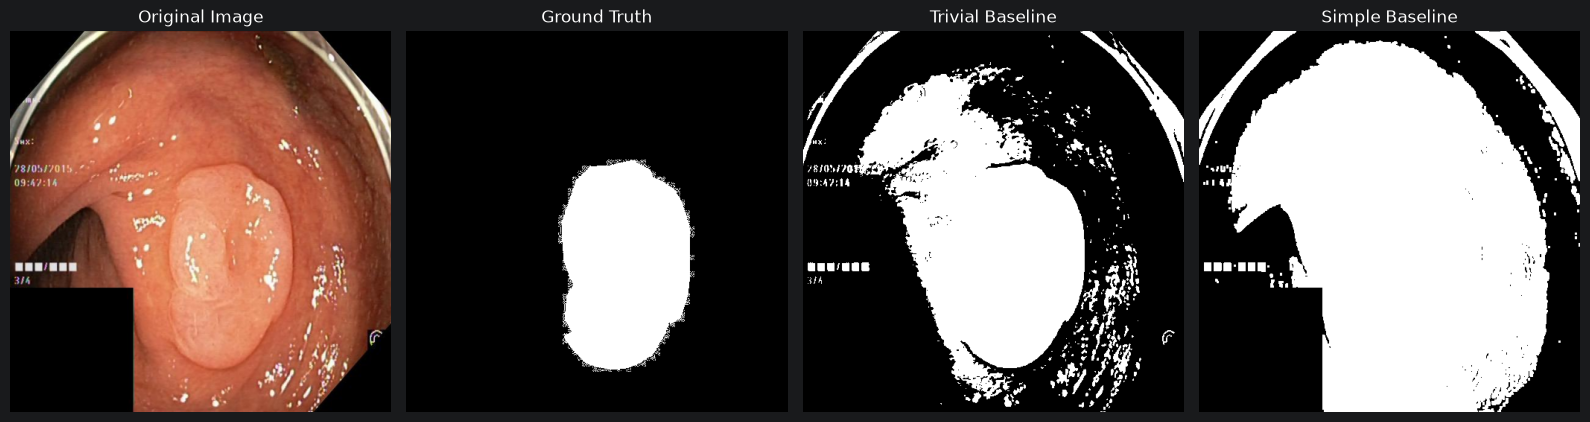

In [44]:
plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(ground_truth, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(trivial_pred, cmap="gray")
plt.title("Trivial Baseline")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(simple_pred, cmap="gray")
plt.title("Simple Baseline")
plt.axis("off")

plt.tight_layout()
plt.show()

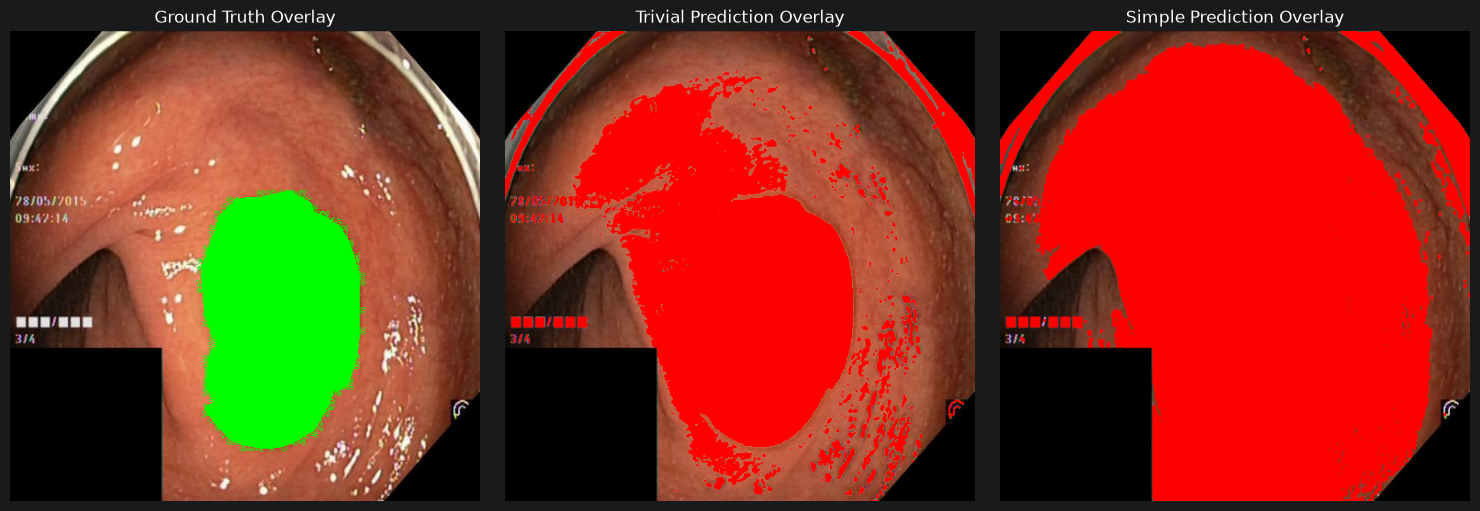

In [45]:
gt_overlay = image.copy()
trivial_overlay = image.copy()
simple_overlay = image.copy()

gt_overlay[ground_truth > 0] = [0, 255, 0]

trivial_overlay[trivial_pred > 0] = [255, 0, 0]

simple_overlay[simple_pred > 0] = [255, 0, 0]

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gt_overlay)
plt.title("Ground Truth Overlay")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(trivial_overlay)
plt.title("Trivial Prediction Overlay")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(simple_overlay)
plt.title("Simple Prediction Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

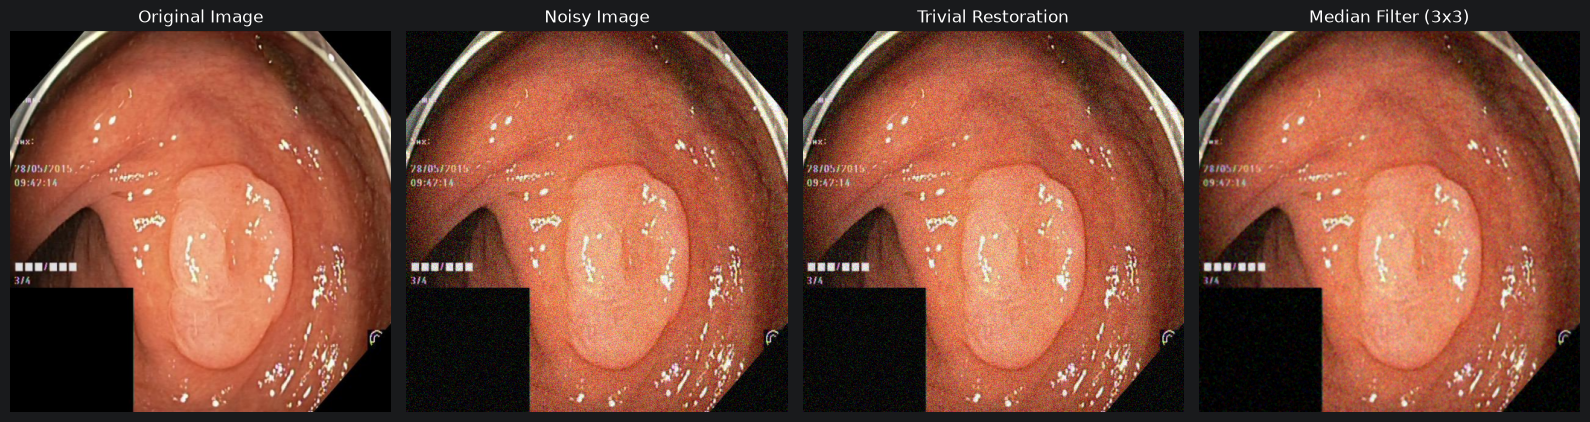

In [46]:
noisy_image = degrade_image(
    image,
    method="gaussian",
    seed=42
)

trivial_restored = trivial_restoration(noisy_image)

simple_restored = simple_restoration(noisy_image)

plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(noisy_image)
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(trivial_restored)
plt.title("Trivial Restoration")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(simple_restored)
plt.title("Median Filter (3x3)")
plt.axis("off")

plt.tight_layout()
plt.show()

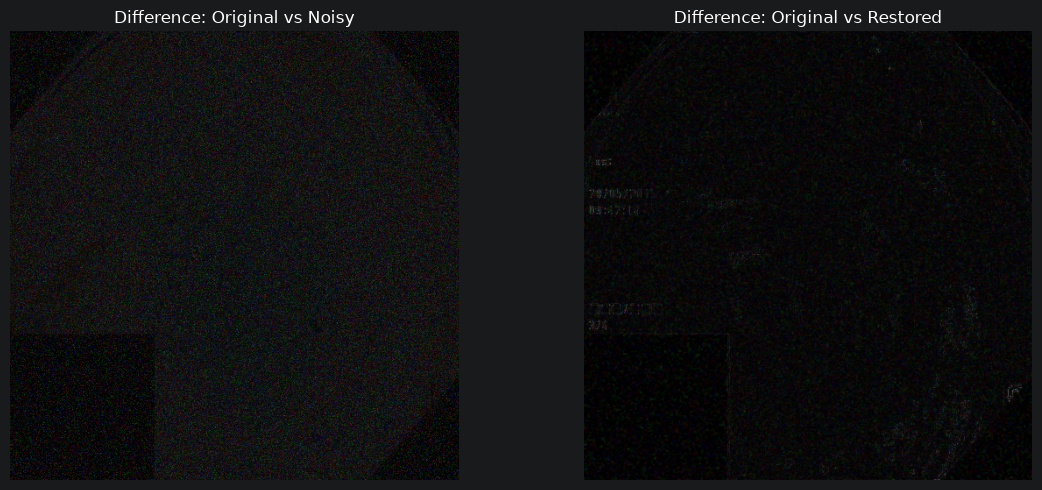

In [47]:
noisy_difference = cv2.absdiff(
    image,
    noisy_image
)

restored_difference = cv2.absdiff(
    image,
    simple_restored
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(noisy_difference)
plt.title("Difference: Original vs Noisy")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(restored_difference)
plt.title("Difference: Original vs Restored")
plt.axis("off")

plt.tight_layout()
plt.show()

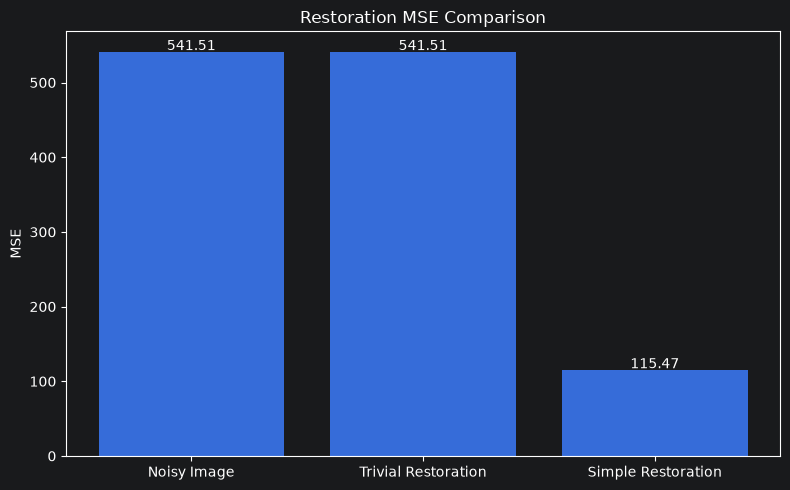

In [48]:
from src.metrics import calculate_mse

noisy_mse = calculate_mse(image, noisy_image)

trivial_mse = calculate_mse(image, trivial_restored)

simple_mse = calculate_mse(image, simple_restored)

plt.figure(figsize=(8, 5))

names = [
    "Noisy Image",
    "Trivial Restoration",
    "Simple Restoration"
]

values = [
    noisy_mse,
    trivial_mse,
    simple_mse
]

bars = plt.bar(names, values)

plt.title("Restoration MSE Comparison")
plt.ylabel("MSE")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

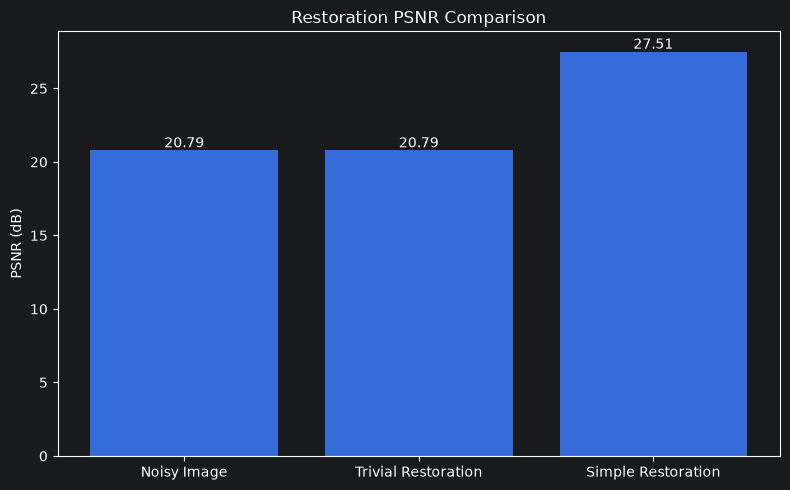

In [49]:
from src.metrics import calculate_psnr

noisy_psnr = calculate_psnr(image, noisy_image)

trivial_psnr = calculate_psnr(image, trivial_restored)

simple_psnr = calculate_psnr(image, simple_restored)

plt.figure(figsize=(8, 5))

names = [
    "Noisy Image",
    "Trivial Restoration",
    "Simple Restoration"
]

values = [
    noisy_psnr,
    trivial_psnr,
    simple_psnr
]

bars = plt.bar(names, values)

plt.title("Restoration PSNR Comparison")
plt.ylabel("PSNR (dB)")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()